# 06 — Final Model Selection and Export for the Application

## Objective
Notebook 05 tuned all six classifiers with the same grouped 5-fold protocol. This notebook:

1. states the **selection rule** and applies it to the Notebook 05 results;
2. refits every model with its best hyperparameters (read from `reports/tuning/`, nothing is re-tuned);
3. exports the selected pipeline and the files read by the Streamlit app (`models/firewall_pipeline.joblib`, `models/metadata.json`, `models/metrics.json`), now with **confusion matrices for all six models**, ROC-AUC and feature importances;
4. exports interpretability material for the report (decision-tree rules and figure).

## Selection rule (decided on training cross-validation only)
1. Keep the models whose CV macro-F1 is statistically indistinguishable from the best one (Friedman test on the paired folds, Notebook 05).
2. Among them, choose the **simplest and fastest** model (Occam's razor): an interpretable model with the lowest inference cost is preferred for a firewall-log tool.

Notebook 05 results: Random Forest 0.8479, KNN 0.8478 and Decision Tree 0.8478 (CV macro-F1); Friedman test on these three: p = 0.63, so there is no significant difference. The **Decision Tree** is the simplest of the three, is directly interpretable as firewall-like rules, and predicts about 80× faster than the Random Forest and 28× faster than KNN. The test set then only confirms the choice: same test macro-F1 as Random Forest, identical predictions (McNemar: 0 discordant flows), and a much higher ROC-AUC than KNN (0.998 vs 0.931).

In [1]:
from pathlib import Path
import sys, json, time, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "preprocessing.py").exists():
    raise FileNotFoundError("Run this notebook from the repository root or from notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")   # keeps absolute local paths out of the saved outputs

from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, average_precision_score, make_scorer)
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
from sklearn.tree import export_text, plot_tree

from src.preprocessing import make_preprocessor, get_feature_columns
from src.models import build_model

RANDOM_STATE = 42
CLASS_LABELS = ["allow", "deny", "drop", "reset-both"]
SELECTED_MODEL = "Decision Tree"            # result of the selection rule above
TUNING = ROOT / "reports" / "tuning"
FIGURES = ROOT / "docs" / "latex" / "figures" / "ch05"
FIGURES.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
test_df = pd.read_csv(ROOT / "data" / "processed" / "test.csv")
FEATURES = get_feature_columns("full")
X_train, y_train = train_df[FEATURES], train_df["Action"].str.strip().str.lower()
X_test, y_test = test_df[FEATURES], test_df["Action"].str.strip().str.lower()
print(f"train {X_train.shape}, test {X_test.shape}, selected model: {SELECTED_MODEL}")

train (45736, 11), test (11434, 11), selected model: Decision Tree


## 1. Best hyperparameters found in Notebook 05

In [2]:
FILES = {"Dummy (Zero-R)": "gridsearch_dummy.csv", "KNN": "gridsearch_knn.csv",
         "Decision Tree": "gridsearch_decision_tree.csv", "Random Forest": "gridsearch_random_forest.csv",
         "Gaussian Naive Bayes": "gridsearch_gaussian_naive_bayes.csv", "SVM (SVC)": "gridsearch_svm.csv"}

def best_row(name):
    res = pd.read_csv(TUNING / FILES[name])
    row = res.sort_values("rank_test_score", kind="stable").iloc[0]   # same tie-break as GridSearchCV.best_index_
    params = eval(row["params"], {"__builtins__": {}}, {"np": np, "nan": np.nan})  # file written by Notebook 05
    params = {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}   # numpy -> plain Python
    return params, row

summary = pd.read_csv(TUNING / "tuning_summary.csv").set_index("model")
best = {}
for name in FILES:
    params, row = best_row(name)
    best[name] = params
    print(f"{name:22s} CV macro-F1 {row['mean_test_score']:.4f} ± {row['std_test_score']:.4f}  {params}")
assert SELECTED_MODEL in best

Dummy (Zero-R)         CV macro-F1 0.2505 ± 0.0055  {'classifier__strategy': 'stratified'}
KNN                    CV macro-F1 0.8478 ± 0.0378  {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance'}
Decision Tree          CV macro-F1 0.8478 ± 0.0379  {'classifier__ccp_alpha': 0.0, 'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1}
Random Forest          CV macro-F1 0.8479 ± 0.0378  {'classifier__class_weight': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Gaussian Naive Bayes   CV macro-F1 0.7076 ± 0.0056  {'classifier__var_smoothing': 1e-05}
SVM (SVC)              CV macro-F1 0.8417 ± 0.0516  {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


## 2. Refit every model with its best hyperparameters and evaluate once on the test set
The SVM is refitted on the same stratified sample used for its search (≤ 4,000 rows per class, all `reset-both` rows).

In [3]:
def make_estimator(name):
    if name == "SVM (SVC)":
        return Pipeline([("preprocessing", make_preprocessor("full")),
                         ("classifier", SVC(random_state=RANDOM_STATE, cache_size=1000))])
    return build_model(name, "full")

def svm_sample(X, y, per_class=4000):
    labels = pd.Series(y.to_numpy(), index=X.index)
    idx = pd.concat([d.sample(min(len(d), per_class), random_state=RANDOM_STATE)
                     for _, d in labels.groupby(labels)]).index
    pos = np.sort(X.index.get_indexer(idx))
    return X.iloc[pos], y.iloc[pos]

def class_scores(model, X):
    s = model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)
    order = [list(model.classes_).index(c) for c in CLASS_LABELS]
    return s[:, order]

Y_bin = label_binarize(y_test, classes=CLASS_LABELS)
fitted, results, matrices = {}, [], {}
for name in summary.sort_values("cv_macro_f1_mean", ascending=False).index:
    model = make_estimator(name).set_params(**best[name])
    Xf, yf = svm_sample(X_train, y_train) if name == "SVM (SVC)" else (X_train, y_train)
    t0 = time.perf_counter(); model.fit(Xf, yf); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = model.predict(X_test); pred_s = time.perf_counter() - t0
    S = class_scores(model, X_test)
    fitted[name] = model
    matrices[name] = confusion_matrix(y_test, y_pred, labels=CLASS_LABELS).tolist()
    results.append({"model": name,
                    "accuracy": accuracy_score(y_test, y_pred),
                    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                    "f1_macro": f1_score(y_test, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
                    "f1_weighted": f1_score(y_test, y_pred, labels=CLASS_LABELS, average="weighted", zero_division=0),
                    "roc_auc_ovr_macro": float(np.mean([roc_auc_score(Y_bin[:, k], S[:, k]) for k in range(4)])),
                    "pr_auc_reset_both": average_precision_score(Y_bin[:, 3], S[:, 3]),
                    "fit_seconds": round(fit_s, 2),
                    "ms_per_1000_rows": round(1000 * pred_s / len(X_test) * 1000, 2)})
test_df_res = pd.DataFrame(results).set_index("model").round(4)
display(test_df_res)

,accuracy,balanced_accuracy,f1_macro,f1_weighted,roc_auc_ovr_macro,pr_auc_reset_both,fit_seconds,ms_per_1000_rows
model,,,,,,,,
Random Forest,0.9985,0.7716,0.7900,0.9981,0.9976,0.1847,3.25,6.74
KNN,0.9984,0.7716,0.7899,0.9981,0.9309,0.1662,0.09,409.19
Decision Tree,0.9985,0.7716,0.7900,0.9981,0.9976,0.1848,0.18,1.32
SVM (SVC),0.9983,0.7715,0.7897,0.9979,0.9960,0.1389,0.13,5.47
Gaussian Naive Bayes,0.9502,0.9177,0.7101,0.9689,0.9926,0.0197,0.11,2.48
Dummy (Zero-R),0.4965,0.2575,0.2574,0.4977,0.4986,0.0010,0.06,1.23


## 3. The selected model: per-class results, feature importance and rules

In [4]:
final_pipeline = fitted[SELECTED_MODEL]
y_pred = final_pipeline.predict(X_test)
report = classification_report(y_test, y_pred, labels=CLASS_LABELS, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))

# Permutation importance on the held-out test set, on the 11 raw input columns
macro_f1 = make_scorer(f1_score, labels=CLASS_LABELS, average="macro", zero_division=0)
perm = permutation_importance(final_pipeline, X_test, y_test, scoring=macro_f1,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importances = (pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean,
                             "std": perm.importances_std})
               .sort_values("importance", ascending=False))
display(importances.round(4))

,precision,recall,f1-score,support
allow,1.0000,1.0000,1.0000,7488.0000
deny,0.9938,0.9956,0.9947,1608.0000
drop,0.9970,1.0000,0.9985,2327.0000
reset-both,1.0000,0.0909,0.1667,11.0000
accuracy,0.9985,0.9985,0.9985,0.9985
macro avg,0.9977,0.7716,0.7900,11434.0000
weighted avg,0.9985,0.9985,0.9981,11434.0000


,feature,importance,std
8,Elapsed Time (sec),0.3429,0.0060
1,Destination Port,0.3156,0.0032
3,NAT Destination Port,0.0451,0.0019
7,Packets,0.0226,0.0160
5,Bytes Sent,0.0202,0.0013
10,pkts_received,0.0002,0.0001
0,Source Port,0.0000,0.0000
2,NAT Source Port,0.0000,0.0000
4,Bytes,0.0000,0.0000
6,Bytes Received,0.0000,0.0000


Tree depth = 14, leaves = 37, encoded features = 80
|--- Elapsed Time (sec) <= -1.04
|   |--- Destination Port_445 <= 0.50
|   |   |--- Packets <= -0.55
|   |   |   |--- NAT Destination Port_53 <= 0.50
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- NAT Destination Port_53 >  0.50
|   |   |   |   |--- class: allow
|   |   |--- Packets >  -0.55
|   |   |   |--- Destination Port_3389 <= 0.50
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- Destination Port_3389 >  0.50
|   |   |   |   |--- class: reset-both
|   |--- Destination Port_445 >  0.50
|   |   |--- Bytes Sent <= -0.72
|   |   |   |--- class: deny
|   |   |--- Bytes Sent >  -0.72
|   |   |   |--- Bytes Sent <= -0.69
|   |   |   |   |--- class: drop
|   |   |   |--- Bytes Sent >  -0.69
|   |   |   |   |--- truncated branch of depth 2
|--- Elapsed Time (sec) >  -1.04
|   |--- Elapsed Time (sec) <= -0.76
|   |   |--- NAT Destination Port_3389 <= 0.50
|   |   |   |--- Destination Port_22 <= 0.50
| 

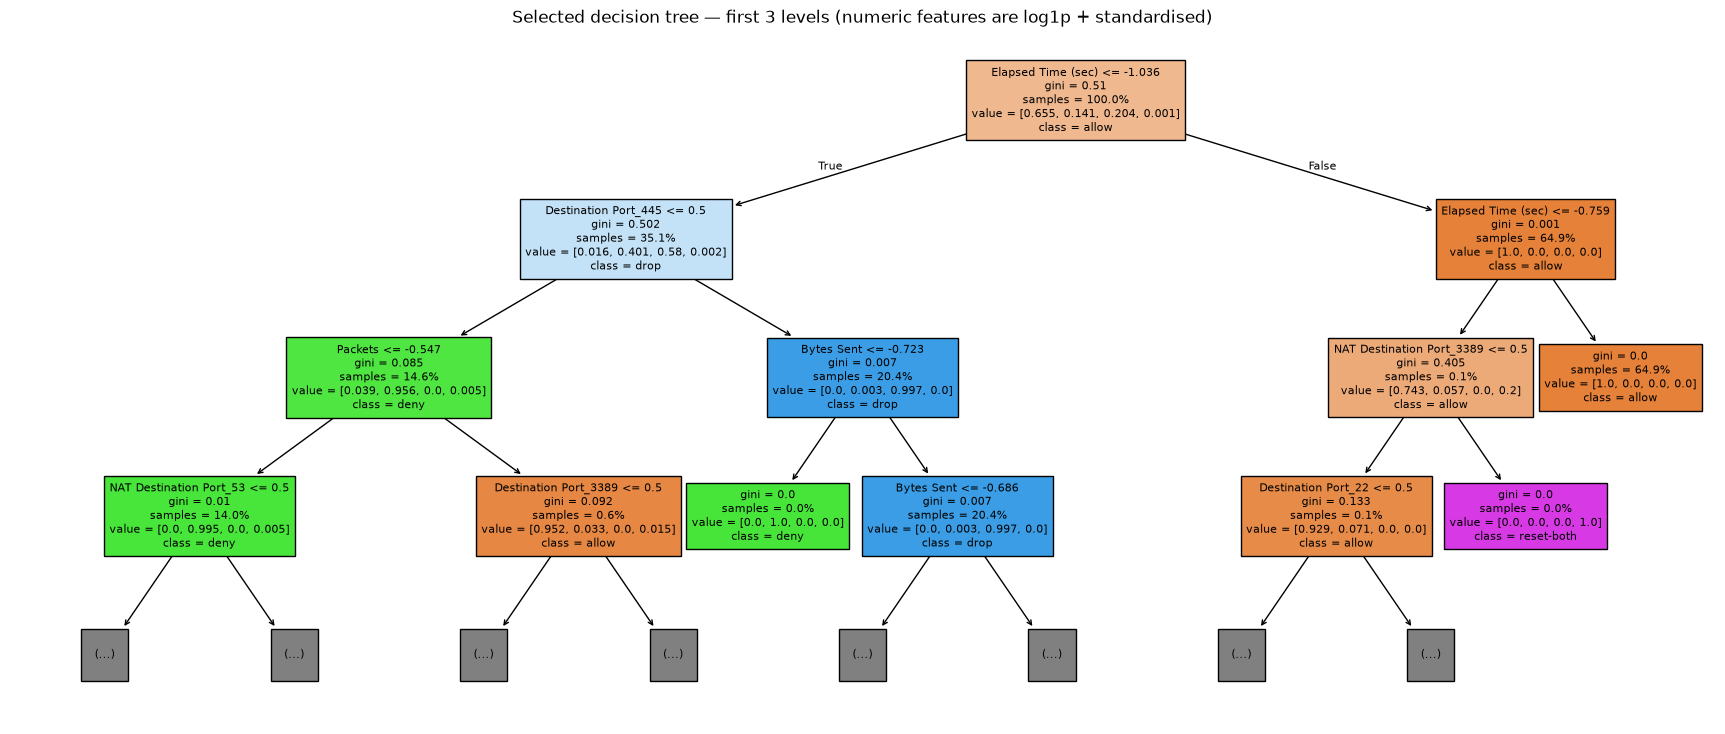

In [5]:
tree = final_pipeline.named_steps["classifier"]
encoded_names = [n.split("__", 1)[-1] for n in final_pipeline.named_steps["preprocessing"].get_feature_names_out()]
print(f"Tree depth = {tree.get_depth()}, leaves = {tree.get_n_leaves()}, encoded features = {len(encoded_names)}")

rules = export_text(tree, feature_names=encoded_names, max_depth=3, decimals=2)
(ROOT / "reports" / "decision_tree_rules_depth3.txt").write_text(rules, encoding="utf-8")
print(rules[:3000])

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=encoded_names, class_names=list(tree.classes_),
          filled=True, impurity=True, proportion=True, fontsize=8, ax=ax)
ax.set_title("Selected decision tree — first 3 levels (numeric features are log1p + standardised)")
fig.savefig(FIGURES / "decision_tree_top3.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Export the artifacts read by the Streamlit application

In [6]:
models_dir, reports_dir = ROOT / "models", ROOT / "reports"
old_metrics = json.loads((models_dir / "metrics.json").read_text(encoding="utf-8")) \
    if (models_dir / "metrics.json").is_file() else {}

joblib.dump(final_pipeline, models_dir / "firewall_pipeline.joblib")

metadata = {
    "project": "Intelligent Firewall Traffic Analyzer",
    "training_source": "data/processed/train.csv",
    "test_source": "data/processed/test.csv",
    "model_name": SELECTED_MODEL,
    "feature_set": "full",
    "feature_columns": FEATURES,
    "class_labels": CLASS_LABELS,
    "random_state": RANDOM_STATE,
    "cv_folds": 5,
    "selection_metric": "macro_f1",
    "selection_rule": "Best CV macro-F1 group (Friedman p = 0.63 between RF, KNN, DT); simplest and fastest model kept.",
    "best_params": best[SELECTED_MODEL],
    "tuning_source": "notebooks/05_full_tuning_benchmark.ipynb",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "warning": "Historical action prediction; full-feature measurements may be post-decision variables.",
}
(models_dir / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")

sel = test_df_res.loc[SELECTED_MODEL]
per_class = [{"class": c, "precision": report[c]["precision"], "recall": report[c]["recall"],
              "f1": report[c]["f1-score"], "support": int(report[c]["support"])} for c in CLASS_LABELS]
cv_rows = []
for name, r in summary.iterrows():
    cv_rows.append({"model": name, "f1_macro_mean": r["cv_macro_f1_mean"], "f1_macro_std": r["cv_macro_f1_std"],
                    "train_f1_macro_mean": r["cv_train_macro_f1"], "n_candidates": int(r["n_candidates"]),
                    "train_rows": int(r["train_rows"]), "seconds": r["search_seconds"]})
model_comparison = [{"model": r["model"], "macro_f1": r["f1_macro_mean"], "cv_mean": r["f1_macro_mean"],
                     "cv_std": r["f1_macro_std"], "train_macro_f1": r["train_f1_macro_mean"],
                     "grid_candidates": r["n_candidates"], "search_time_sec": r["seconds"],
                     "best_params": str({k.replace("classifier__", ""): v for k, v in best[r["model"]].items()})}
                    for r in cv_rows]
ordered = [SELECTED_MODEL] + [m for m in test_df_res.index if m != SELECTED_MODEL]   # app shows the first one

metrics_payload = {
    "model_name": SELECTED_MODEL,
    "accuracy": sel["accuracy"], "balanced_accuracy": sel["balanced_accuracy"],
    "macro_f1": sel["f1_macro"], "weighted_f1": sel["f1_weighted"],
    "class_labels": CLASS_LABELS,
    "confusion_matrix": matrices[SELECTED_MODEL],
    "confusion_matrices": {m: {"class_labels": CLASS_LABELS, "matrix": matrices[m]} for m in ordered},
    "per_class": per_class,
    "model_comparison": model_comparison,
    "test": {k: float(sel[k]) for k in ["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted",
                                         "roc_auc_ovr_macro", "pr_auc_reset_both"]},
    "test_model_comparison": test_df_res.reset_index().to_dict(orient="records"),
    "cv_model_comparison": cv_rows,
    "cv_feature_ablation": old_metrics.get("cv_feature_ablation", []),
    "feature_importances": importances[["feature", "importance"]].to_dict(orient="records"),
}
(models_dir / "metrics.json").write_text(json.dumps(metrics_payload, indent=2, default=float), encoding="utf-8")

pd.DataFrame(report).T.to_csv(reports_dir / "classification_report.csv")
test_df_res.to_csv(reports_dir / "final_test_comparison.csv")
importances.to_csv(reports_dir / "permutation_importance_final_model.csv", index=False)
print("Exported:", [p.name for p in models_dir.iterdir()])

Exported: ['metrics.json', 'README.md', 'metadata.json', 'firewall_pipeline.joblib']


## 5. Integration smoke test

In [7]:
reloaded = joblib.load(ROOT / "models" / "firewall_pipeline.joblib")
assert (reloaded.predict(X_test) == y_pred).all(), "reloaded pipeline differs from the in-memory one"
saved = json.loads((ROOT / "models" / "metrics.json").read_text(encoding="utf-8"))
assert saved["model_name"] == SELECTED_MODEL and len(saved["cv_model_comparison"]) == 6
print("OK: reloaded pipeline gives identical predictions; metrics.json has", len(saved["confusion_matrices"]), "confusion matrices.")

OK: reloaded pipeline gives identical predictions; metrics.json has 6 confusion matrices.


## 6. Conclusion (for the report, chapter 5)

- All tuned models except Naive Bayes and Zero-R reach the same CV macro-F1 (≈ 0.848), and the Friedman test does not separate the top three models.
- The **Decision Tree** is selected for the application by the simplicity/latency rule; on the test set it matches the Random Forest exactly and has a far better ROC-AUC than KNN.
- The remaining error is concentrated in `reset-both`: 10 of the 11 test flows are predicted as `deny` by every strong model. Naive Bayes is the only model that recalls all of them, but at the cost of labelling about 31 % of `deny` flows as `reset-both`. This is a precision/recall trade-off that the report must discuss.